# Reading Data

## Read Raw Data Anggota

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib

ROOT = Path.cwd()

DATA = ROOT / "data"

SENTINELS = ["", "NA", "N/A", "-", "null", "NULL", "unknown", "-999"]

raw_anggota = pd.read_csv(
    DATA / "anggota.csv",
    sep=",",                                  # the actual delimiter
    dtype={"store_id": "string"},             # preserve leading zeros
    na_values=SENTINELS,                      # declare the folk sentinels
    keep_default_na=True,
    decimal=".",                              # ...and the decimal
    parse_dates=["tanggal_daftar"],
    dayfirst=True,                            # 03/04/2023 is 3 April
)
print("shape:", raw_anggota.shape)
print(raw_anggota.dtypes.to_string())
raw_anggota.head(3)

shape: (1500, 9)
id_anggota                   int64
usia                         int64
kota                           str
tanggal_daftar      datetime64[us]
tingkat                        str
pakai_aplikasi                 str
penghasilan_juta           float64
voucher_winback              int64
berhenti                       str


,id_anggota,usia,kota,tanggal_daftar,tingkat,pakai_aplikasi,penghasilan_juta,voucher_winback,berhenti
0,354,41,Yogyakarta,2023-12-12,Silver,ya,11.8,0,tidak
1,1496,20,Sleman,2025-11-12,Silver,ya,8.8,0,tidak
2,2805,35,Bantul,2024-08-05,Silver,ya,3.9,0,tidak


## Read Raw Data Transaksi

In [10]:
raw_transaksi = pd.read_csv(
    DATA / "transaksi.csv",
    sep=",",                                  # the actual delimiter
    dtype={"store_id": "string"},             # preserve leading zeros
    na_values=SENTINELS,                      # declare the folk sentinels
    keep_default_na=True,
    decimal=".",                              # ...and the decimal
    parse_dates=["waktu"],                            # 03/04/2023 is 3 April
)
print("shape:", raw_transaksi.shape)
print(raw_transaksi.dtypes.to_string())
raw_transaksi.head(3)

shape: (36175, 9)
id_transaksi               str
id_anggota               int64
waktu           datetime64[us]
cabang                     str
kategori                   str
jumlah_item              int64
total                    int64
pakai_promo                str
metode_bayar               str


,id_transaksi,id_anggota,waktu,cabang,kategori,jumlah_item,total,pakai_promo,metode_bayar
0,T009292,3569,2026-02-14 21:03:00,C08,kopi,1,29700,tidak,QRIS
1,T019288,318,2026-04-11 07:08:00,C07,non-kopi,3,75900,tidak,aplikasi
2,T032136,998,2026-06-15 13:33:00,C10,kopi,2,43300,tidak,aplikasi


# Profiling Data

In [ ]:
def profile(df):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(dropna=True),
        "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None
                    for c in df.columns],
    })
    return out.sort_values("pct_missing", ascending=False)


profile(raw_anggota)

,dtype,n_missing,pct_missing,n_unique,example
penghasilan_juta,float64,138,9.2,160,11.8
id_anggota,int64,0,0.0,1500,354
usia,int64,0,0.0,53,41
tanggal_daftar,datetime64[us],0,0.0,826,2023-12-12 00:00:00
kota,str,0,0.0,19,Yogyakarta
tingkat,str,0,0.0,3,Silver
pakai_aplikasi,str,0,0.0,2,ya
voucher_winback,int64,0,0.0,2,0
berhenti,str,0,0.0,2,tidak


In [13]:
profile(raw_transaksi)

,dtype,n_missing,pct_missing,n_unique,example
id_transaksi,str,0,0.0,35640,T009292
id_anggota,int64,0,0.0,1559,3569
waktu,datetime64[us],0,0.0,31393,2026-02-14 21:03:00
cabang,str,0,0.0,20,C08
kategori,str,0,0.0,3,kopi
jumlah_item,int64,0,0.0,21,1
total,int64,0,0.0,1734,29700
pakai_promo,str,0,0.0,2,tidak
metode_bayar,str,0,0.0,3,QRIS


## Check Duplication Data

### Check Duplication Anggota

In [20]:
print(f"rows            : {len(raw_anggota):,}")
print(f"exact duplicates: {raw_anggota.duplicated().sum():,}")
print(f"duplicate anggota: {raw_anggota.duplicated(subset='id_anggota').sum():,}")
print()
print(raw_anggota[["tingkat", "berhenti"]].describe().T)

rows            : 1,500
exact duplicates: 0
duplicate anggota: 0

         count unique     top  freq
tingkat   1500      3  Silver  1050
berhenti  1500      2   tidak  1269


### Check Duplication Transaksi

In [26]:
print(f"rows            : {len(raw_transaksi):,}")
print(f"exact duplicates: {raw_transaksi.duplicated().sum():,}")
print(f"duplicate orders: {raw_transaksi.duplicated(subset='id_transaksi').sum():,}")
print()
print(raw_transaksi[raw_transaksi.duplicated(subset='id_transaksi', keep=False)].sort_values(by='id_transaksi').head(10))

rows            : 36,175
exact duplicates: 535
duplicate orders: 535

      id_transaksi  id_anggota               waktu cabang  kategori  \
27310      T000075        2430 2026-01-01 10:07:00    C15  non-kopi   
9296       T000075        2430 2026-01-01 10:07:00    C15  non-kopi   
22491      T000096        2338 2026-01-01 12:03:00    C03   makanan   
13512      T000096        2338 2026-01-01 12:03:00    C03   makanan   
5433       T000113        2860 2026-01-01 13:02:00    C14      kopi   
24826      T000113        2860 2026-01-01 13:02:00    C14      kopi   
33225      T000134        2895 2026-01-01 15:01:00    C07      kopi   
15907      T000134        2895 2026-01-01 15:01:00    C07      kopi   
9416       T000226        1805 2026-01-01 21:35:00    C08      kopi   
9830       T000226        1805 2026-01-01 21:35:00    C08      kopi   

       jumlah_item   total pakai_promo metode_bayar  
27310            1   27600       tidak     aplikasi  
9296             1   27600       tidak  

Ternyata ditemukan sebanyak 535 data yang terduplikasi dan harus dilakukan cleaning data.

# Cleaning Data Transaksi

### Drop Data Duplication on id_transaksi

In [118]:
df_transaksi = raw_transaksi.copy()
n0 = len(df_transaksi)

# --- step 1: duplicates ------------------------------------------------
df_transaksi = df_transaksi.drop_duplicates(subset="id_transaksi", keep="first")
print(f"after dedup: {len(df_transaksi):,} rows  (removed {n0 - len(df_transaksi):,})")

after dedup: 35,640 rows  (removed 535)


### Ubah ketidaksesuaian data Kota pada Data Anggota

In [119]:
print("kota, before:", sorted(raw_anggota["kota"].unique()))
df_anggota = raw_anggota.copy()

kota_valid = ['Yogyakarta', 'Bantul', 'Gunungkidul', 'Kulonprogo', 'Sleman']

df_anggota["kota"] = (df_anggota["kota"].str.strip().str.title()
                            .replace({"": np.nan}))

mapping_kota = {
    'Jogja': 'Yogyakarta',
    'Yogya': 'Yogyakarta',
    'Kulon Progo': 'Kulonprogo',
    'Gunung Kidul':'Gunungkidul'
}

df_anggota['kota'] = df_anggota['kota'].replace(mapping_kota)

print("kota, after :", sorted(df_anggota["kota"].dropna().unique()))
print("missing kota:", df_anggota["kota"].isna().sum())

kota, before: ['BANTUL', 'Bantul', 'Bantul ', 'Gunung Kidul', 'Gunungkidul', 'Jogja', 'Kulon Progo', 'Kulonprogo', 'SLEMAN', 'Sleman', 'Sleman ', 'YOGYAKARTA', 'Yogya', 'Yogyakarta', 'bantul', 'gunungkidul', 'kulon progo', 'sleman', 'yogyakarta']
kota, after : ['Bantul', 'Gunungkidul', 'Kulonprogo', 'Sleman', 'Yogyakarta']
missing kota: 0


### Make NaN impossible data

In [120]:
bad_usia = (df_anggota["usia"] <= 0).sum() + (df_anggota["usia"] > 100).sum()
bad_total = (df_transaksi["total"] <= 0).sum()
print(f"impossible usia: {bad_usia}   impossible total: {bad_total}")

df_anggota.loc[df_anggota["usia"] <= 0, "usia"] = np.nan
df_anggota.loc[df_anggota["usia"] > 100, "usia"] = np.nan
df_transaksi.loc[df_transaksi["total"] <= 0, "total"] = np.nan

print("data after check validity")
bad_usia_after = (df_anggota["usia"] <= 0).sum() + (df_anggota["usia"] > 100).sum()
bad_total_after = (df_transaksi["total"] <= 0).sum()
print(f"impossible usia: {bad_usia_after}   impossible total: {bad_total_after}")

impossible usia: 44   impossible total: 12
data after check validity
impossible usia: 0   impossible total: 0


# Check Missing Data

In [121]:
df_anggota['penghasilan_missing'] = df_anggota['penghasilan_juta'].isna()
print('total data penghasilan tidak kosong: ', df_anggota['penghasilan_juta'].count())
print('jumlah data penghasilan kosong: ', df_anggota['penghasilan_missing'].sum())

total data penghasilan tidak kosong:  1362
jumlah data penghasilan kosong:  138


In [122]:
print("Is missingness associated with the observed variables?\n")
print("by kota:")
print((df_anggota.groupby("kota", observed=True)["penghasilan_missing"]
         .agg(["mean", "size"]).rename(columns={"mean": "pct_missing"})
         .assign(pct_missing=lambda d: (d.pct_missing * 100).round(2))))
print("\nby tingkat:")
print((df_anggota.groupby("tingkat", observed=True)["penghasilan_missing"]
         .mean().mul(100).round(2)))
print("\nmean berhenti, missing vs observed penghasilan:")
print(df_anggota.groupby("penghasilan_missing")["usia"].mean().round(3))

Is missingness associated with the observed variables?

by kota:
             pct_missing  size
kota                          
Bantul              8.02   262
Gunungkidul         6.76    74
Kulonprogo          9.64    83
Sleman              9.47   581
Yogyakarta          9.80   500

by tingkat:
tingkat
Gold        8.67
Platinum    5.33
Silver      9.90
Name: penghasilan_missing, dtype: float64

mean berhenti, missing vs observed penghasilan:
penghasilan_missing
False    31.667
True     42.754
Name: usia, dtype: float64


Karena data tersebut ternyata dipengaruhi oleh variable lain, yaitu **Usia** maka bisa dikatakan **MAR**, kemudian dilakukan impute agar data tetap aman.

### Impute the data penghasilan_juta dengan KNNImputer

Menggunakan KNNImputer karena data tersebut bergantung pada **tingkat** dan juga **usia**, tidak bisa hanya menggunakan data kota saja sebagai dasar untuk perbaikan data penghasilan anggota.

In [123]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# 1. Siapkan salinan data agar data asli tidak langsung berubah berantakan
df_model = df_anggota[['usia', 'tingkat', 'penghasilan_juta']].copy()

# 2. Ubah kolom kategorikal ('tingkat') menjadi numerik menggunakan One-Hot Encoding
df_model = pd.get_dummies(df_model, columns=['tingkat'], drop_first=False)

# 3. Lakukan Scaling (Penting agar 'penghasilan' yang nilainya jutaan tidak mendominasi 'usia' yang hanya puluhan)
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_model), columns=df_model.columns)

# 4. Terapkan KNNImputer (misal kita cari 5 tetangga terdekat / n_neighbors=5)
imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = imputer.fit_transform(df_scaled)

# 5. Kembalikan data ke skala aslinya (Inverse Scaling)
df_imputed_original = scaler.inverse_transform(df_imputed_scaled)
df_result = pd.DataFrame(df_imputed_original, columns=df_model.columns)

# 6. Masukkan kembali hasil imputasi 'penghasilan_juta' DAN 'usia' ke DataFrame awal
df_anggota['penghasilan_juta'] = df_result['penghasilan_juta']
df_anggota['usia'] = df_result['usia'].round() # Dibulatkan karena usia berupa bilangan bulat

print('Cek NaN penghasilan_juta:', df_anggota['penghasilan_juta'].isna().sum())
print('Cek NaN usia:', df_anggota['usia'].isna().sum())

Cek NaN penghasilan_juta: 0
Cek NaN usia: 0


## Check nilai total yang tidak wajar

In [124]:
max_total = df_transaksi['total'].max()
min_total = df_transaksi['total'].min()
mean_total = df_transaksi['total'].mean()
median_total = df_transaksi['total'].median()
q1_total = df_transaksi['total'].quantile(0.25)
q3_total = df_transaksi['total'].quantile(0.75)

print('max total: ', max_total)
print('min total: ', min_total)
print('mean total: ', mean_total)
print('median total: ', median_total)
print('Q1 total: ', q1_total)
print('Q3 total: ', q3_total)

max total:  35000000.0
min total:  7100.0
mean total:  56978.63618502302
median total:  38300.0
Q1 total:  25500.0
Q3 total:  62800.0


In [125]:
transaksi_aneh = df_transaksi.loc[df_transaksi['total'] > 1000000,
                                  ['id_transaksi', 'id_anggota', 'kategori', 'jumlah_item', 'total']]

print(f"Jumlah baris tidak wajar: {len(transaksi_aneh)}")
print(transaksi_aneh)

Jumlah baris tidak wajar: 26
      id_transaksi  id_anggota  kategori  jumlah_item       total
710        T033833        1323  non-kopi            1  28000000.0
885        T008108        1012  non-kopi            1  35000000.0
1876       T010999        3531      kopi            1  33000000.0
3570       T008769         935      kopi          120   2693520.0
4217       T024479        1164      kopi          120   2907840.0
8029       T018710        3950   makanan            1  29000000.0
8123       T022001        3226   makanan           74   1768230.0
10639      T016533         501      kopi            1  22000000.0
13875      T035568        1181  non-kopi           64   1486784.0
13946      T016270        1812      kopi            1  25000000.0
14855      T018161        2081  non-kopi            1  35000000.0
15307      T011820        1570      kopi           87   2145681.0
15728      T001695        2091      kopi            1  33000000.0
18881      T004444        3674   makanan       

In [126]:
transaksi_aneh = df_transaksi.loc[(df_transaksi['total'] > 1000000) & (df_transaksi['jumlah_item'] == 1),
                                  ['id_transaksi', 'id_anggota', 'kategori', 'jumlah_item', 'total']]

print(f"Jumlah baris tidak wajar: {len(transaksi_aneh)}")
print(transaksi_aneh)

Jumlah baris tidak wajar: 9
      id_transaksi  id_anggota  kategori  jumlah_item       total
710        T033833        1323  non-kopi            1  28000000.0
885        T008108        1012  non-kopi            1  35000000.0
1876       T010999        3531      kopi            1  33000000.0
8029       T018710        3950   makanan            1  29000000.0
10639      T016533         501      kopi            1  22000000.0
13946      T016270        1812      kopi            1  25000000.0
14855      T018161        2081  non-kopi            1  35000000.0
15728      T001695        2091      kopi            1  33000000.0
34855      T010279        3182      kopi            1  29000000.0


Dikarenakan total pembayaran yang tidak wajar tersebut adalah kesalahan pencatatan, yaitu **jumlah item** hanya 1 dengan **total di atas 1 juta**. Maka nilai total dengan **jutaan** diganti nilai menjadi **ribuan**

In [127]:
total_edit = (df_transaksi['total'] > 1000000) & (df_transaksi['jumlah_item'] == 1)

df_transaksi.loc[total_edit, 'total'] = df_transaksi.loc[total_edit, 'total'] / 1000

print(df_transaksi.loc[total_edit,['id_transaksi', 'id_anggota', 'kategori', 'jumlah_item', 'total']])

      id_transaksi  id_anggota  kategori  jumlah_item    total
710        T033833        1323  non-kopi            1  28000.0
885        T008108        1012  non-kopi            1  35000.0
1876       T010999        3531      kopi            1  33000.0
8029       T018710        3950   makanan            1  29000.0
10639      T016533         501      kopi            1  22000.0
13946      T016270        1812      kopi            1  25000.0
14855      T018161        2081  non-kopi            1  35000.0
15728      T001695        2091      kopi            1  33000.0
34855      T010279        3182      kopi            1  29000.0


# Joining Data Anggota dengan Data Transaksi

### Use merge on pandas to be joining data

In [155]:
# 1. Bersihkan dulu 12 transaksi yang 'total'-nya NaN di df_transaksi
df_transaksi_bersih = df_transaksi.dropna(subset=['total']).copy()

# 2. Gunakan how='inner' saat membuat df_gabung!
# Ini otomatis membuang 240 transaksi yang id_anggota-nya tidak terdaftar di df_anggota
df_gabung = pd.merge(df_transaksi_bersih, df_anggota, on='id_anggota', how='inner')
df_gabung['penghasilan_missing'] = df_gabung['penghasilan_juta'].isna()

# Menampilkan beberapa baris pertama dan informasi kolom hasil gabungan
print("Cek ulang NaN di df_gabung (sekarang harus 0 semua):")
print(df_gabung.isna().sum())

print(df_gabung.head())
print(df_gabung.info())



Cek ulang NaN di df_gabung (sekarang harus 0 semua):
id_transaksi           0
id_anggota             0
waktu                  0
cabang                 0
kategori               0
jumlah_item            0
total                  0
pakai_promo            0
metode_bayar           0
usia                   0
kota                   0
tanggal_daftar         0
tingkat                0
pakai_aplikasi         0
penghasilan_juta       0
voucher_winback        0
berhenti               0
penghasilan_missing    0
dtype: int64
  id_transaksi  id_anggota               waktu cabang  kategori  jumlah_item  \
0      T009292        3569 2026-02-14 21:03:00    C08      kopi            1   
1      T019288         318 2026-04-11 07:08:00    C07  non-kopi            3   
2      T032136         998 2026-06-15 13:33:00    C10      kopi            2   
3      T026989         712 2026-05-22 12:53:00    C15      kopi            4   
4      T025743         208 2026-05-15 14:59:00    C12      kopi            1   

   

# Membuat Graph dari data yang sudah di join

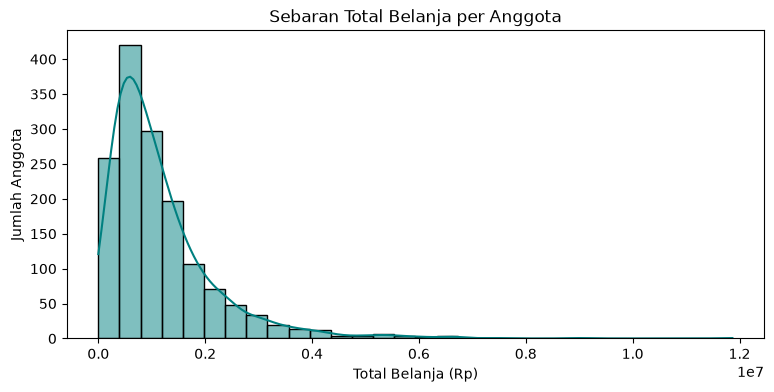

Rata-rata (Mean): 1,166,207.43
Median: 885,350.00


In [156]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung total belanja per anggota
df_belanja = df_transaksi_bersih.groupby('id_anggota')['total'].sum().reset_index()
df_full = pd.merge(df_anggota, df_belanja, on='id_anggota', how='left').fillna({'total': 0})

# Grafik 1: Sebaran Total Belanja
plt.figure(figsize=(9, 4))
sns.histplot(df_full['total'], bins=30, kde=True, color='teal')
plt.title('Sebaran Total Belanja per Anggota')
plt.xlabel('Total Belanja (Rp)')
plt.ylabel('Jumlah Anggota')
plt.show()

# Menghitung statistik
mean_val = df_full['total'].mean()
median_val = df_full['total'].median()
print(f"Rata-rata (Mean): {mean_val:,.2f}")
print(f"Median: {median_val:,.2f}")

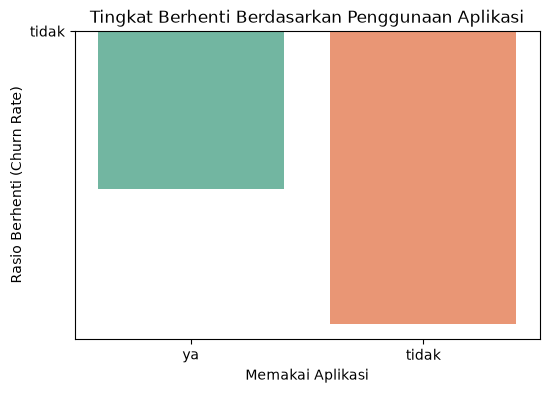

In [165]:
# Grafik 2: Churn Rate Berdasarkan Penggunaan Aplikasi
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df_gabung, 
    x='pakai_aplikasi', 
    y='berhenti', 
    hue='pakai_aplikasi',
    legend=False,
    palette='Set2', 
    errorbar=None
)

plt.title('Tingkat Berhenti Berdasarkan Penggunaan Aplikasi')
plt.xlabel('Memakai Aplikasi')
plt.ylabel('Rasio Berhenti (Churn Rate)')
plt.show()

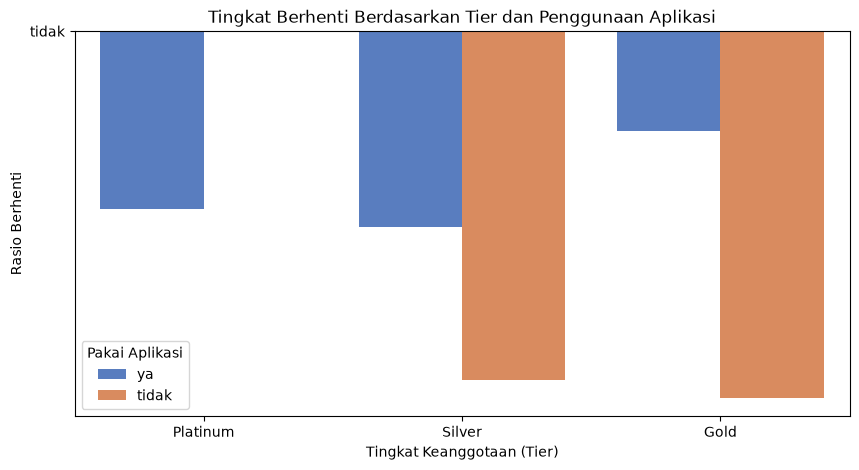

In [164]:
# Grafik 3: Analisis Variabel Ketiga (Tingkat Keanggotaan)
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_gabung, 
    x='tingkat', 
    y='berhenti', 
    hue='pakai_aplikasi', 
    palette='muted', 
    errorbar=None
)

ax.legend(title='Pakai Aplikasi')

plt.title('Tingkat Berhenti Berdasarkan Tier dan Penggunaan Aplikasi')
plt.xlabel('Tingkat Keanggotaan (Tier)')
plt.ylabel('Rasio Berhenti')
plt.legend(title='Pakai Aplikasi')
plt.show()

# Menghitung Probability

### Menghitung Probability Berhenti berdasarkan Pengguna Aplikasi

In [163]:
# normalize=True otomatis mengubah jumlah hitungan menjadi probabilitas (0 sampai 1)
probabilitas = df_gabung.groupby('pakai_aplikasi')['berhenti'].value_counts(normalize=True)

print("Probabilitas Berhenti:")
print(probabilitas)

Probabilitas Berhenti:
pakai_aplikasi  berhenti
tidak           tidak       0.819524
                ya          0.180476
ya              tidak       0.902746
                ya          0.097254
Name: proportion, dtype: float64


### Melakukan z-test

In [166]:
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# Menyiapkan data sukses (berhenti) dan total sampel per kelompok
# Ubah kolom 'berhenti' menjadi biner (1 untuk berhenti, 0 tidak) jika belum
berhenti_biner = df_gabung['berhenti'].apply(lambda x: 1 if x in ['ya', 1, True] else 0)
app_biner = df_gabung['pakai_aplikasi'].apply(lambda x: 1 if x in ['ya', '1', True] else 0)

# Kelompok 1: Memakai aplikasi, Kelompok 2: Tidak memakai aplikasi
n1 = (app_biner == 1).sum()
n2 = (app_biner == 0).sum()
s1 = berhenti_biner[app_biner == 1].sum()
s2 = berhenti_biner[app_biner == 0].sum()

# Uji Hipotesis Dua Proporsi
z_stat, p_value = proportions_ztest([s1, s2], [n1, n2], alternative='smaller')
print(f"Z-statistic: {z_stat:.4f}, p-value: {p_value:.4f}")

# Selang Kepercayaan 95% untuk selisih proporsi (p1 - p2)
import numpy as np
from statsmodels.stats.api import zconfint
# Menggunakan proporsi standar
p1 = s1 / n1
p2 = s2 / n2
se_diff = np.sqrt((p1*(1-p1)/n1) + (p2*(1-p2)/n2))
diff = p1 - p2
ci_lower = diff - 1.96 * se_diff
ci_upper = diff + 1.96 * se_diff

print(f"Selisih Proporsi (Pengguna - Non-pengguna): {diff:.4f}")
print(f"Selang Kepercayaan 95%: [{ci_lower:.4f}, {ci_upper:.4f}]")

Z-statistic: -21.2619, p-value: 0.0000
Selisih Proporsi (Pengguna - Non-pengguna): -0.0832
Selang Kepercayaan 95%: [-0.0918, -0.0746]


**Z-statistic** tersebut menandakan bahwa terdapat **perbedaan** yang mencolok antara pengguna aplikasi dan tidak menggunakan aplikasi

**Selisih proporsi** menandakan bahwa tingkat berhenti berlangganan pada kelompok yang memakai aplikasi adalah **10%** (0.1000) lebih rendah dibandingkan mereka yang tidak memakai aplikasi.

Berdasarkan hasil tersebut, maka dapat ditarik kesimpulan bahwa **aplikasi dapat mengurangi resiko berhentinya pelanggan**.

# Features

### Recency, Frequency, dan Monetary

In [167]:
asof = df_gabung["waktu"].max()
print("feature cutoff (as-of date):", asof)

feats = df_gabung.groupby("id_anggota").agg(
    n_tx=("total", "size"),
    total=("total", "sum"),
    mean_amt=("total", "mean"),
    std_amt=("total", "std"),
    max_amt=("total", "max"),
    first_ts=("waktu", "min"),
    last_ts=("waktu", "max"),
    n_categories=("kategori", "nunique"),
)

# Recency, Frequency, Monetary -- the classic RFM triple
feats["recency_days"] = (asof - feats["last_ts"]).dt.days
feats["tenure_days"] = (asof - feats["first_ts"]).dt.days
feats["tx_per_month"] = feats["n_tx"] / (feats["tenure_days"] / 30).clip(lower=1)

# Dispersion relative to level: a scale-free measure of erratic spending
feats["cv_amt"] = feats["std_amt"] / feats["mean_amt"]

# Category concentration: is this a specialist or a generalist?
share = df_gabung.pivot_table(index="id_anggota", columns="kategori",
                       values="total", aggfunc="sum", fill_value=0)
feats["top_cat_share"] = share.max(axis=1) / share.sum(axis=1)

# Trend: recent behaviour relative to the customer's own baseline
recent = df_gabung[df_gabung["waktu"] > asof - pd.Timedelta(days=90)]
feats["recent_vs_overall"] = (recent.groupby("id_anggota")["total"].mean()
                              / feats["mean_amt"]).fillna(0)

cols = ["n_tx", "mean_amt", "cv_amt", "recency_days", "tx_per_month",
        "top_cat_share", "recent_vs_overall"]
print(feats[cols].describe().round(3).T.to_string())

feature cutoff (as-of date): 2026-06-30 21:55:00
                    count       mean        std        min        25%        50%        75%         max
n_tx               1499.0     23.608     18.669      1.000     11.000     19.000     29.000     191.000
mean_amt           1499.0  48969.255  18681.610  15633.333  36999.405  45967.925  56930.000  268609.000
cv_amt             1497.0      0.580      0.293      0.033      0.492      0.554      0.613       4.477
recency_days       1499.0     14.354     20.887      0.000      2.000      6.000     18.000     153.000
tx_per_month       1499.0      4.195      3.207      0.203      2.060      3.418      5.140      32.191
top_cat_share      1499.0      0.621      0.129      0.352      0.529      0.612      0.703       1.000
recent_vs_overall  1499.0      0.982      0.239      0.000      0.900      0.996      1.080       2.459


> #### 1. cv_amt (Coefficient of Variation of Amount / Variasi Belanja)
>Fitur ini mengukur seberapa stabil atau fluktuatif/acak kebiasaan belanja seorang anggota. Jika angkanya mendekati 0, berarti anggota tersebut selalu berbelanja dengan nominal yang konsisten (misalnya, selalu beli es kopi susu seharga Rp20.000 setiap datang).

>#### 2. top_cat_share (Category Concentration / Konsentrasi Kategori)
>Fitur ini mengukur seberapa fanatik/spesialis seorang pelanggan terhadap satu jenis produk saja.

>#### 3. recent_vs_overall (Spending Trend / Tren Belanja Terbaru)
>Fitur ini mendeteksi momentum/tren apakah pelanggan sedang makin sering berbelanja atau justru perlahan mulai pergi (*cooling down*). Jika skornya < 1.0: Pelanggan sedang "menurun" (belanjanya mulai menurun dibanding kebiasaan lamanya).

### Encoding dan Scalling Features

In [136]:
from sklearn.preprocessing import RobustScaler

# 1. Pilih kolom-kolom numerik yang ingin di-scale (termasuk RFM dan fitur baru)
kolom_numerik = ['cv_amt', 'top_cat_share', 'recent_vs_overall', 
                 'tx_per_month', 'recency_days', 'mean_amt']

# 2. Inisialisasi RobustScaler
scaler = RobustScaler()

# 3. Terapkan scaling dan simpan kembali ke bentuk DataFrame agar rapi
feats_scaled = pd.DataFrame(
    scaler.fit_transform(feats[kolom_numerik]), 
    columns=kolom_numerik, 
    index=feats.index
)

# Cek hasilnya
print(feats_scaled.head())

               cv_amt  top_cat_share  recent_vs_overall  tx_per_month  \
id_anggota                                                              
5           -0.315277      -1.085450           0.086816      0.647150   
6            0.716359       0.530668          -0.140833      1.122999   
8            2.749745       1.651070          -2.629754     -0.681804   
11          22.505361       0.895693          -3.412936      0.914209   
15           0.296691      -1.125105           1.623270      0.319644   

            recency_days  mean_amt  
id_anggota                          
5              -0.235294 -0.561540  
6               0.000000  0.816840  
8               4.588235 -1.022419  
11              0.294118  1.678030  
15              0.352941  1.224993  


>Karena features sudah **berbentuk angka**, maka **tidak diperlukan encoding**.

>Scalling menggunakan **Robust Scaler**

# Mencari data leakage

### Mencari data leakage menggunakan korelasi
> jika lebih dari 0.5 bahkan sampai 1.0, maka bisa dicurigai sebagai data leakage

In [168]:
# Ubah target ke angka 1 dan 0
target_biner = (df_gabung['berhenti'] == 'ya').astype(int)

# Hitung korelasi semua kolom numerik terhadap target
korelasi = df_gabung.select_dtypes(include='number').apply(lambda x: x.corr(target_biner))
print(korelasi.sort_values(ascending=False))

voucher_winback     0.792518
penghasilan_juta    0.015120
id_anggota          0.010815
jumlah_item         0.002446
total              -0.011342
usia               -0.033669
dtype: float64


> Berdasarkan data tersebut, maka ***voucher_winback*** dapat kita curigai sebagai **data leakage**.

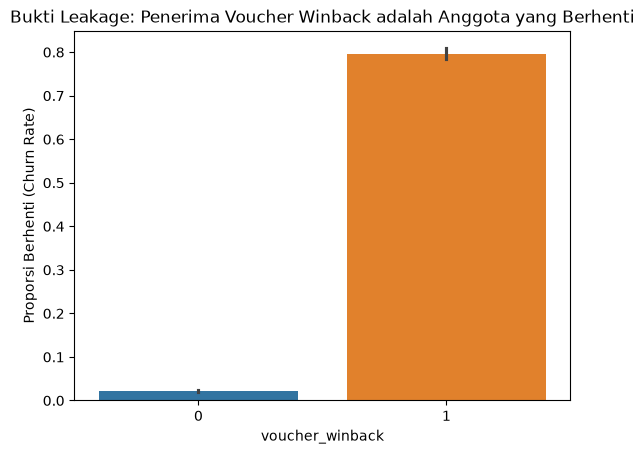

In [169]:
sns.barplot(
    data=df_gabung, 
    x='voucher_winback', 
    y=(df_gabung['berhenti'] == 'ya').astype(int),
    hue='voucher_winback',
    legend=False
)
plt.ylabel('Proporsi Berhenti (Churn Rate)')
plt.title('Bukti Leakage: Penerima Voucher Winback adalah Anggota yang Berhenti')
plt.show()

> Setelah data leakage telah diketahui, selanjutnya adalah  membandingkan dengan  *5-fold cross-validation* dan *ROC-AUC*

In [170]:
# Cek jumlah NaN di setiap kolom yang akan dimasukkan ke model
print("Jumlah NaN per kolom di feats:")
print(feats.isna().sum())

print("\nJumlah NaN per kolom di df_anggota:")
print(df_gabung[['usia', 'tingkat', 'pakai_aplikasi', 'penghasilan_juta', 'kota']].isna().sum())

Jumlah NaN per kolom di feats:
n_tx                 0
total                0
mean_amt             0
std_amt              2
max_amt              0
first_ts             0
last_ts              0
n_categories         0
recency_days         0
tenure_days          0
tx_per_month         0
cv_amt               2
top_cat_share        0
recent_vs_overall    0
dtype: int64

Jumlah NaN per kolom di df_anggota:
usia                0
tingkat             0
pakai_aplikasi      0
penghasilan_juta    0
kota                0
dtype: int64


> Khusus untuk fitur *cv_amt (std_amt / mean_amt)*, nilai **NaN** muncul karena anggota tersebut **baru berbelanja 1 kali** sehingga **standar deviasinya tidak terdefinisi**. Secara logika, jika baru belanja 1 kali, variasi belanjanya memang 0.

In [171]:
feats['std_amt'] = feats['std_amt'].fillna(0)
feats['cv_amt'] = feats['cv_amt'].fillna(0)


> Cek lagi Jumlah NaN

In [172]:
# Cek jumlah NaN di setiap kolom yang akan dimasukkan ke model
print("Jumlah NaN per kolom di feats:")
print(feats.isna().sum())

print("\nJumlah NaN per kolom di df_anggota:")
print(df_gabung[['usia', 'tingkat', 'pakai_aplikasi', 'penghasilan_juta', 'kota']].isna().sum())

Jumlah NaN per kolom di feats:
n_tx                 0
total                0
mean_amt             0
std_amt              0
max_amt              0
first_ts             0
last_ts              0
n_categories         0
recency_days         0
tenure_days          0
tx_per_month         0
cv_amt               0
top_cat_share        0
recent_vs_overall    0
dtype: int64

Jumlah NaN per kolom di df_anggota:
usia                0
tingkat             0
pakai_aplikasi      0
penghasilan_juta    0
kota                0
dtype: int64


In [175]:
df_model_final = pd.merge(df_anggota, feats, on='id_anggota', how='inner')

print("\nJumlah anggota siap dievaluasi di 5-Fold CV:", len(df_model_final))
print("Total NaN di df_model_final:", df_model_final.isna().sum().sum())


Jumlah anggota siap dievaluasi di 5-Fold CV: 1499
Total NaN di df_model_final: 0


# Evaluasi 5-fold Cross Validation dan RUC-AOC

In [180]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
import pandas as pd
import numpy as np

# 1. Siapkan Target (y)
y = df_model_final['berhenti'].apply(lambda x: 1 if x == 'ya' else 0)

# 2. Definisikan Himpunan Fitur (X)
# (A) Kolom tabel anggota saja (tanpa target, tanpa ID, tanpa variabel bocor)
fitur_A = ['usia', 'tingkat', 'pakai_aplikasi', 'penghasilan_juta', 'kota'] # Sesuaikan dengan nama kolom Anda
# (B) A ditambah Frequency dan Monetary (asumsi dari feats yang sudah dibuat)
fitur_B = fitur_A + ['n_tx', 'total']
# (C) B ditambah fitur lainnya (Advanced Analytics)
fitur_C = fitur_B + ['cv_amt', 'top_cat_share', 'recent_vs_overall', 'tx_per_month', 'recency_days']

X_full = df_model_final[fitur_C].copy()

# 3. Setup Preprocessing dalam Pipeline untuk mencegah Data Leakage
def get_preprocessor(fitur_kategorik, fitur_numerik):
    return ColumnTransformer(
        transformers=[
            ('num', RobustScaler(), fitur_numerik),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), fitur_kategorik)
        ])

# 4. Setup Model
models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'LogReg': LogisticRegression(max_iter=1000)
}

# 5. Eksekusi 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil = []

# Asumsi kita punya fungsi deteksi otomatis mana kategorik/numerik dari list fitur
for nama_himpunan, list_fitur in [('Tabel Anggota Saja', fitur_A), ('Ditambah Frequency dan Monetary', fitur_B), ('Ditambah Fitur Lainnya', fitur_C)]:
    fitur_num = X_full[list_fitur].select_dtypes(include=np.number).columns.tolist()
    fitur_cat = X_full[list_fitur].select_dtypes(exclude=np.number).columns.tolist()
    
    preprocessor = get_preprocessor(fitur_cat, fitur_num)
    
    for nama_model, model in models.items():
        # PIPELINE: Menjamin scaling dilakukan HANYA pada data fold training di tiap iterasi
        clf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
        
        # Hitung ROC-AUC
        scores = cross_val_score(clf, X_full[list_fitur], y, cv=cv, scoring='roc_auc')
        hasil.append({
            'Himpunan Fitur': nama_himpunan,
            'Model': nama_model,
            'Mean ROC-AUC': scores.mean().round(4),
            'Std ROC-AUC': scores.std().round(4)
        })

# Sajikan Tabel
df_hasil = pd.DataFrame(hasil)
print(df_hasil.pivot(index='Himpunan Fitur', columns='Model', values='Mean ROC-AUC'))

Model                               KNN  LogReg
Himpunan Fitur                                 
Ditambah Fitur Lainnya           0.7209  0.7977
Ditambah Frequency dan Monetary  0.5448  0.6248
Tabel Anggota Saja               0.5490  0.6078


### PCA pada data yang sudah dievaluasi

In [181]:
from sklearn.decomposition import PCA

# 1. Ambil HANYA fitur numerik murni dari himpunan terlengkap (C)
# Pastikan tidak ada data kosong, bisa diisi mean/median dulu jika ada
X_num = X_full[fitur_C].select_dtypes(include=np.number).fillna(0)

# 2. PCA WAJIB diawali dengan Scaling
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_num)

# 3. Jalankan PCA (tidak membatasi n_components dulu untuk melihat variansi total)
pca = PCA()
pca.fit(X_scaled)

# 4. Hitung berapa komponen untuk mencapai 90% variansi
kumulatif_variansi = np.cumsum(pca.explained_variance_ratio_)
n_komponen_90 = np.argmax(kumulatif_variansi >= 0.90) + 1 # ditambah 1 karena index dimulai dari 0
print(f"Jumlah komponen untuk mencapai 90% variansi: {n_komponen_90} komponen")

# 5. Cek isi/loading dari Komponen Utama Pertama (PC1)
loadings_pc1 = pca.components_[0]
df_loadings = pd.DataFrame({
    'Fitur': X_num.columns,
    'Loading_PC1': loadings_pc1,
    'Abs_Loading': np.abs(loadings_pc1)
}).sort_values(by='Abs_Loading', ascending=False)

print("\nIsi Komponen Pertama (PC1) berdasarkan pengaruhnya:")
print(df_loadings.head(5))

Jumlah komponen untuk mencapai 90% variansi: 5 komponen

Isi Komponen Pertama (PC1) berdasarkan pengaruhnya:
          Fitur  Loading_PC1  Abs_Loading
4        cv_amt     0.968818     0.968818
3         total     0.172919     0.172919
7  tx_per_month     0.099909     0.099909
2          n_tx     0.099776     0.099776
8  recency_days    -0.075511     0.075511


# Menyimpan file Data Model ke .csv

In [182]:
import os
# Daftar kolom fitur lengkap (Himpunan C) ditambah id_anggota dan target 'berhenti'
kolom_simpan = ['id_anggota'] + fitur_C + ['berhenti']

# Simpan ke CSV tanpa index
file_path = os.path.join('data', 'df_model_final.csv')
df_model_final[kolom_simpan].to_csv(file_path, index=False)